# Assignment 2: Module 1, Fuzzy Logic

---

## Practical 6: Fuzzy IF-THEN Rules for Decision Making

### Aim
To write simple fuzzy IF-THEN rules and use them to make a decision from crisp inputs.

### Theory
A fuzzy rule has the form *IF* (condition) *THEN* (conclusion). The steps are:
1. **Fuzzification**: find the membership of each input in its terms.
2. **Rule evaluation**: the firing strength of a rule is found from its conditions. AND uses min and OR uses max.
3. **Implication**: each conclusion's fuzzy set is clipped at the firing strength.
4. **Aggregation**: the clipped sets are combined with max.
5. **Defuzzification**: a single crisp output is found (here, the centroid).

The example is a fan controller with inputs Temperature and Humidity and output Fan speed.

Rules used:
- R1: IF Temperature is High AND Humidity is High THEN Fan is Fast
- R2: IF Temperature is Medium AND Humidity is Medium THEN Fan is Medium
- R3: IF Temperature is Low AND Humidity is Low THEN Fan is Slow
- R4: IF Temperature is High AND Humidity is Low THEN Fan is Medium

### Implementation


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz

# 1. Universes
temp_u = np.arange(0, 41, 1)
hum_u = np.arange(0, 101, 1)
fan_u = np.arange(0, 101, 1)

# 2. Membership functions for each term
temp_mf = {
    "Low": fuzz.trimf(temp_u, [0, 0, 20]),
    "Medium": fuzz.trimf(temp_u, [10, 20, 30]),
    "High": fuzz.trimf(temp_u, [20, 40, 40]),
}
hum_mf = {
    "Low": fuzz.trimf(hum_u, [0, 0, 50]),
    "Medium": fuzz.trimf(hum_u, [25, 50, 75]),
    "High": fuzz.trimf(hum_u, [50, 100, 100]),
}
fan_mf = {
    "Slow": fuzz.trimf(fan_u, [0, 0, 50]),
    "Medium": fuzz.trimf(fan_u, [25, 50, 75]),
    "Fast": fuzz.trimf(fan_u, [50, 100, 100]),
}


In [2]:
def fuzzy_fan_control(temp_val, hum_val):
    # Step 1: fuzzification
    t = {term: fuzz.interp_membership(temp_u, mf, temp_val) for term, mf in temp_mf.items()}
    h = {term: fuzz.interp_membership(hum_u, mf, hum_val) for term, mf in hum_mf.items()}

    # Step 2: rule firing strengths (AND = min) and their conclusions
    rules = [
        (min(t["High"], h["High"]), "Fast", "R1"),
        (min(t["Medium"], h["Medium"]), "Medium", "R2"),
        (min(t["Low"], h["Low"]), "Slow", "R3"),
        (min(t["High"], h["Low"]), "Medium", "R4"),
    ]

    print(f"Temperature = {temp_val} C, Humidity = {hum_val} %")
    for strength, term, name in rules:
        print(f"  {name}: strength = {strength:.2f}, fan = {term}")

    # Step 3 and 4: clip each conclusion and aggregate with max
    aggregated = np.zeros_like(fan_u, dtype=float)
    for strength, term, _ in rules:
        aggregated = np.fmax(aggregated, np.fmin(strength, fan_mf[term]))

    # Step 5: defuzzify with centroid
    crisp = fuzz.defuzz(fan_u, aggregated, "centroid")
    print(f"  Fan speed = {crisp:.1f} %\n")
    return aggregated, crisp


In [3]:
# 3. Test three input cases
results = []
for temp_val, hum_val in [(35, 90), (22, 50), (5, 20)]:
    results.append((temp_val, hum_val, fuzzy_fan_control(temp_val, hum_val)))


Temperature = 35 C, Humidity = 90 %
  R1: strength = 0.75, fan = Fast
  R2: strength = 0.00, fan = Medium
  R3: strength = 0.00, fan = Slow
  R4: strength = 0.00, fan = Medium
  Fan speed = 82.5 %

Temperature = 22 C, Humidity = 50 %
  R1: strength = 0.00, fan = Fast
  R2: strength = 0.80, fan = Medium
  R3: strength = 0.00, fan = Slow
  R4: strength = 0.00, fan = Medium
  Fan speed = 50.0 %

Temperature = 5 C, Humidity = 20 %
  R1: strength = 0.00, fan = Fast
  R2: strength = 0.00, fan = Medium
  R3: strength = 0.60, fan = Slow
  R4: strength = 0.00, fan = Medium
  Fan speed = 18.6 %



### Visualization


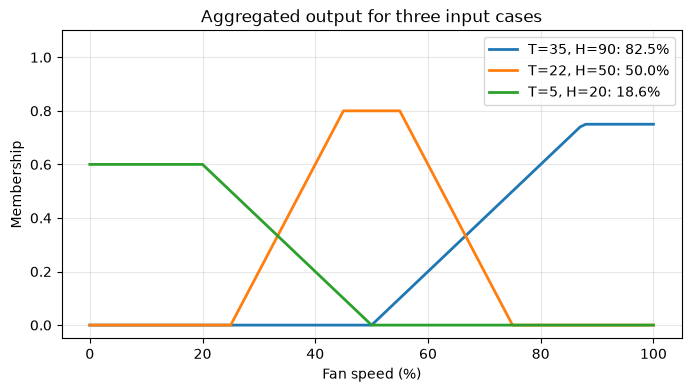

In [4]:
plt.figure(figsize=(8, 4))
for temp_val, hum_val, (aggregated, crisp) in results:
    plt.plot(fan_u, aggregated, linewidth=2,
             label=f"T={temp_val}, H={hum_val}: {crisp:.1f}%")

plt.xlabel("Fan speed (%)")
plt.ylabel("Membership")
plt.title("Aggregated output for three input cases")
plt.ylim(-0.05, 1.1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Observation
- At 35 C and 90 % humidity, R1 fires with strength 0.75, and the fan speed is 82.5 %.
- At 22 C and 50 % humidity, R2 fires with strength 0.80, and the fan speed is 50.0 %.
- At 5 C and 20 % humidity, R3 fires with strength 0.60, and the fan speed is 18.6 %.
- Hotter and more humid inputs give a faster fan, which matches the rules.

### Conclusion
Fuzzy IF-THEN rules were evaluated with min for AND, clipped, aggregated with max, and defuzzified with the centroid method to get a crisp fan speed.
